In [1]:
import torch
print("GPU available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU available: True
Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q "/content/drive/MyDrive/mini project/archive.zip" -d /content/data
!find /content/data -maxdepth 4 -type d

/content/data
/content/data/CAMO-V.1.0-CVIU2019
/content/data/CAMO-V.1.0-CVIU2019/Overlaid_Mask
/content/data/CAMO-V.1.0-CVIU2019/Overlaid_Mask/style2
/content/data/CAMO-V.1.0-CVIU2019/Overlaid_Mask/style1
/content/data/CAMO-V.1.0-CVIU2019/GT
/content/data/CAMO-V.1.0-CVIU2019/Images
/content/data/CAMO-V.1.0-CVIU2019/Images/Test
/content/data/CAMO-V.1.0-CVIU2019/Images/Train


In [ ]:
BASE = "/content/data/CAMO-V.1.0-CVIU2019"
!ls "$BASE"
!echo "Train:" && ls "$BASE/Images/Train" | wc -l
!echo "Test:" && ls "$BASE/Images/Test" | wc -l
!echo "GT:" && ls "$BASE/GT" | wc -l
!ls "$BASE/Images/Train" | head -3
!ls "$BASE/GT" | head -3

GT  Images  Overlaid_Mask  README.md
Train:
1000
Test:
250
GT:
1250
camourflage_00001.jpg
camourflage_00002.jpg
camourflage_00003.jpg
camourflage_00001.png
camourflage_00002.png
camourflage_00003.png


In [ ]:
import os, random, json

BASE = "/content/data/CAMO-V.1.0-CVIU2019"
GT_DIR = f"{BASE}/GT"
masks = {os.path.splitext(f)[0]: os.path.join(GT_DIR, f) for f in os.listdir(GT_DIR)}

def make_pairs(folder):
    pairs = []
    for f in sorted(os.listdir(folder)):
        stem = os.path.splitext(f)[0]
        if stem in masks:
            pairs.append((os.path.join(folder, f), masks[stem]))
    return pairs

train_all = make_pairs(f"{BASE}/Images/Train")
test      = make_pairs(f"{BASE}/Images/Test")
print("train_all:", len(train_all), "| test:", len(test))

random.seed(42)
random.shuffle(train_all)
cut = int(0.85 * len(train_all))
train, val = train_all[:cut], train_all[cut:]
print(f"train={len(train)}, val={len(val)}, test={len(test)}")

with open("/content/drive/MyDrive/mini project/split.json", "w") as f:
    json.dump({"train": train, "val": val, "test": test}, f)

train_all: 1000 | test: 250
train=850, val=150, test=250


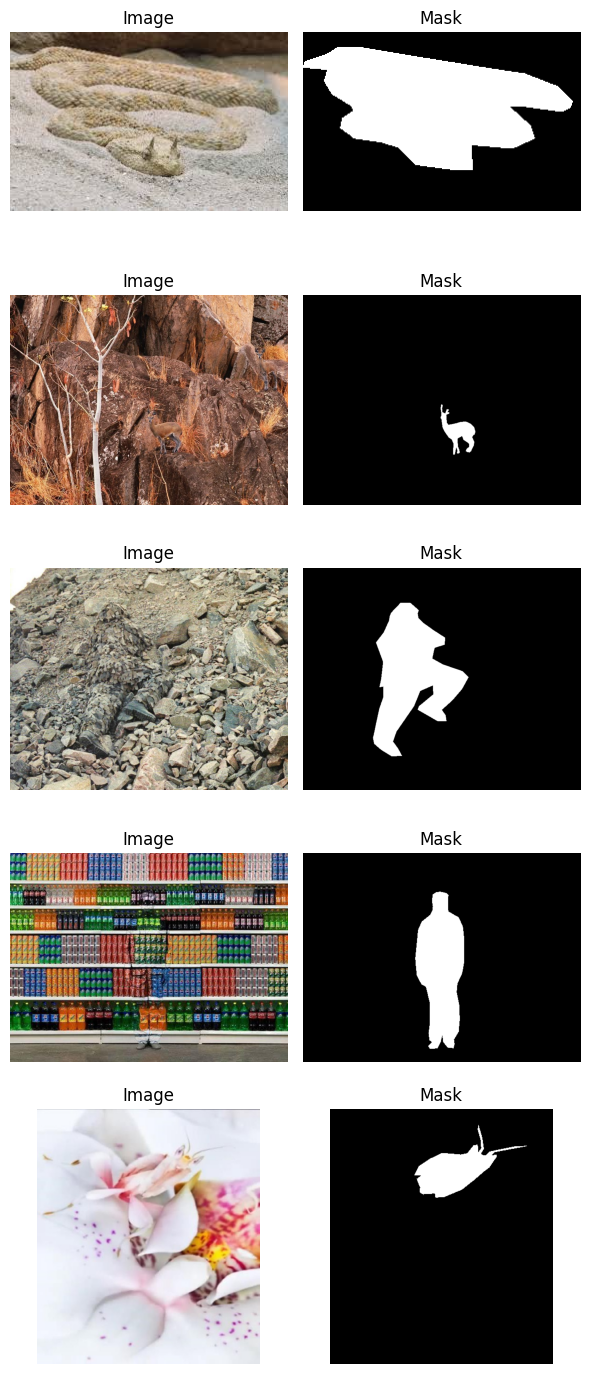

In [ ]:
import cv2, matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 2, figsize=(6, 14))
for i, (img_p, mask_p) in enumerate(train[:5]):
    img  = cv2.cvtColor(cv2.imread(img_p), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
    axes[i, 0].imshow(img);  axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(mask, cmap="gray"); axes[i, 1].set_title("Mask"); axes[i, 1].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
!pip install -q segmentation-models-pytorch

In [ ]:
import json, cv2, torch, numpy as np
from torch.utils.data import Dataset, DataLoader

SPLIT = "/content/drive/MyDrive/mini project/split.json"
with open(SPLIT) as f:
    sp = json.load(f)

SIZE = 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class CamoDS(Dataset):
    def __init__(self, pairs, train=False):
        self.pairs, self.train = pairs, train
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        ip, mp = self.pairs[i]
        img  = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        img  = cv2.resize(img,  (SIZE, SIZE), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (SIZE, SIZE), interpolation=cv2.INTER_NEAREST)
        if self.train and np.random.rand() < 0.5:      # simple augmentation: horizontal flip
            img, mask = img[:, ::-1], mask[:, ::-1]
        img  = (img.astype(np.float32) / 255.0 - MEAN) / STD
        mask = (mask > 127).astype(np.float32)
        img  = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))
        mask = torch.from_numpy(np.ascontiguousarray(mask))[None]
        return img, mask

train_dl = DataLoader(CamoDS(sp["train"], True),  batch_size=16, shuffle=True,  num_workers=2)
val_dl   = DataLoader(CamoDS(sp["val"]),          batch_size=16, shuffle=False, num_workers=2)

x, y = next(iter(train_dl))
print("image batch:", x.shape, "| mask batch:", y.shape, "| mask values:", y.unique())

image batch: torch.Size([16, 3, 256, 256]) | mask batch: torch.Size([16, 1, 256, 256]) | mask values: tensor([0., 1.])


In [ ]:
import os, csv
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS = 30
CKPT_BEST = "/content/drive/MyDrive/mini project/best_model.pth"
CKPT_LAST = "/content/drive/MyDrive/mini project/last_ckpt.pth"
LOG_CSV   = "/content/drive/MyDrive/mini project/train_log.csv"

model = smp.Unet(encoder_name="resnet18", encoder_weights="imagenet",
                 in_channels=3, classes=1).to(device)
opt   = torch.optim.Adam(model.parameters(), lr=3e-4)
sched = CosineAnnealingLR(opt, T_max=EPOCHS)

start_ep, best = 1, 0.0
if os.path.exists(CKPT_LAST):                      # resume
    ck = torch.load(CKPT_LAST, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"])
    start_ep, best = ck["epoch"] + 1, ck["best"]
    print(f"Resuming from epoch {start_ep}, best IoU so far {best:.4f}")
else:
    with open(LOG_CSV, "w", newline="") as f:
        csv.writer(f).writerow(["epoch", "train_loss", "val_iou"])

for ep in range(start_ep, EPOCHS + 1):
    model.train(); tl = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        tl += loss.item()
    sched.step()
    model.eval(); vi = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            vi += batch_iou(model(x), y)
    tl /= len(train_dl); vi /= len(val_dl)
    print(f"Epoch {ep}/{EPOCHS} | train loss {tl:.4f} | val IoU {vi:.4f}")
    with open(LOG_CSV, "a", newline="") as f:
        csv.writer(f).writerow([ep, round(tl, 4), round(vi, 4)])
    if vi > best:
        best = vi
        torch.save(model.state_dict(), CKPT_BEST)
        print("  saved best model")
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(),
                "sched": sched.state_dict(), "epoch": ep, "best": best}, CKPT_LAST)

Resuming from epoch 3, best IoU so far 0.4874
Epoch 3/30 | train loss 0.5054 | val IoU 0.5378
  saved best model
Epoch 4/30 | train loss 0.4441 | val IoU 0.5247
Epoch 5/30 | train loss 0.3732 | val IoU 0.5445
  saved best model
Epoch 6/30 | train loss 0.3546 | val IoU 0.5484
  saved best model
Epoch 7/30 | train loss 0.3151 | val IoU 0.5254
Epoch 8/30 | train loss 0.2908 | val IoU 0.5588
  saved best model
Epoch 9/30 | train loss 0.2602 | val IoU 0.5637
  saved best model
Epoch 10/30 | train loss 0.2386 | val IoU 0.5727
  saved best model
Epoch 11/30 | train loss 0.2262 | val IoU 0.5906
  saved best model
Epoch 12/30 | train loss 0.2132 | val IoU 0.5682
Epoch 13/30 | train loss 0.2234 | val IoU 0.5622
Epoch 14/30 | train loss 0.2059 | val IoU 0.5862
Epoch 15/30 | train loss 0.1958 | val IoU 0.5515
Epoch 16/30 | train loss 0.1877 | val IoU 0.5826
Epoch 17/30 | train loss 0.1647 | val IoU 0.5709
Epoch 18/30 | train loss 0.1503 | val IoU 0.5766
Epoch 19/30 | train loss 0.1510 | val IoU 0.

    epoch  train_loss  val_iou
27     28      0.1205   0.5782
28     29      0.1159   0.5844
29     30      0.1187   0.5873
Best val IoU 0.5952 at epoch 26


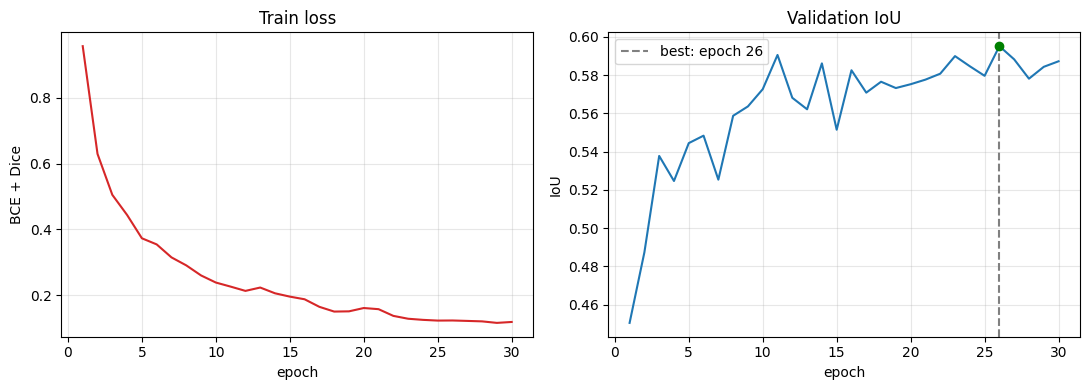

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

D = "/content/drive/MyDrive/mini project"
df = pd.read_csv(f"{D}/train_log.csv")
df = df.drop_duplicates("epoch", keep="last").sort_values("epoch")   # resume se duplicate rows hon to hata do
print(df.tail(3))

best = df.loc[df.val_iou.idxmax()]
print(f"Best val IoU {best.val_iou:.4f} at epoch {int(best.epoch)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(df.epoch, df.train_loss, color="tab:red")
ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("BCE + Dice")
ax[0].grid(alpha=0.3)

ax[1].plot(df.epoch, df.val_iou, color="tab:blue")
ax[1].axvline(best.epoch, color="gray", linestyle="--", label=f"best: epoch {int(best.epoch)}")
ax[1].scatter([best.epoch], [best.val_iou], color="green", zorder=3)
ax[1].set_title("Validation IoU"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("IoU")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{D}/training_curves.png", dpi=150)
plt.show()

In [4]:
import json, shutil, os

D = "/content/drive/MyDrive/mini project"
with open(f"{D}/split.json") as f:
    sp = json.load(f)

shutil.rmtree("/content/handoff", ignore_errors=True)
os.makedirs("/content/handoff/test_images")
os.makedirs("/content/handoff/test_masks")
for ip, mp in sp["test"][:12]:
    shutil.copy(ip, "/content/handoff/test_images/")
    shutil.copy(mp, "/content/handoff/test_masks/")
shutil.copy(f"{D}/best_model.pth", "/content/handoff/")
shutil.make_archive(f"{D}/priyanshu_package", "zip", "/content/handoff")
print("Done")

Done


In [8]:
!pip install -q segmentation-models-pytorch

In [9]:
import json, cv2, torch, numpy as np, pandas as pd
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

D = "/content/drive/MyDrive/mini project"
device = "cuda" if torch.cuda.is_available() else "cpu"
with open(f"{D}/split.json") as f:
    sp = json.load(f)

SIZE = 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def load_img(path, use_clahe):
    img = cv2.imread(path)
    if use_clahe:
        l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
        img = cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_LINEAR)

class TestDS(Dataset):
    def __init__(self, pairs, use_clahe=False):
        self.pairs, self.use_clahe = pairs, use_clahe
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        ip, mp = self.pairs[i]
        img = load_img(ip, self.use_clahe)
        mask = cv2.resize(cv2.imread(mp, cv2.IMREAD_GRAYSCALE), (SIZE, SIZE),
                          interpolation=cv2.INTER_NEAREST)
        x = torch.from_numpy(((img.astype(np.float32) / 255.0 - MEAN) / STD).transpose(2, 0, 1))
        y = torch.from_numpy((mask > 127).astype(np.float32))[None]
        return x, y, i

model = smp.Unet(encoder_name="resnet18", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(torch.load(f"{D}/best_model.pth", map_location=device))
model = model.to(device).eval()

def evaluate(use_clahe=False):
    dl = DataLoader(TestDS(sp["test"], use_clahe), batch_size=16, shuffle=False)
    rows = []
    with torch.no_grad():
        for x, y, idx in dl:
            pred = (torch.sigmoid(model(x.to(device))) > 0.5).float().cpu()
            for p_, g_, i in zip(pred, y, idx):
                tp = (p_ * g_).sum().item()
                fp = (p_ * (1 - g_)).sum().item()
                fn = ((1 - p_) * g_).sum().item()
                rows.append((int(i), tp / (tp + fp + fn + 1e-7),
                             tp / (tp + fp + 1e-7), tp / (tp + fn + 1e-7)))
    return pd.DataFrame(rows, columns=["idx", "iou", "precision", "recall"])

results = {}
for flag in [False, True]:
    df = evaluate(flag); results[flag] = df
    print(f"CLAHE={flag}: IoU {df.iou.mean():.4f} | precision {df.precision.mean():.4f} | "
          f"recall {df.recall.mean():.4f} | images with IoU>=0.5: {(df.iou >= 0.5).mean()*100:.1f}%")

results[False].to_csv(f"{D}/test_results.csv", index=False)
print("saved test_results.csv")

CLAHE=False: IoU 0.4965 | precision 0.7304 | recall 0.6229 | images with IoU>=0.5: 52.0%
CLAHE=True: IoU 0.4922 | precision 0.7016 | recall 0.6257 | images with IoU>=0.5: 51.6%
saved test_results.csv


In [10]:
# val pe probabilities ek baar nikaalo
dl = DataLoader(TestDS(sp["val"], False), batch_size=16, shuffle=False)
probs, gts = [], []
with torch.no_grad():
    for x, y, _ in dl:
        probs.append(torch.sigmoid(model(x.to(device))).cpu()); gts.append(y)
probs, gts = torch.cat(probs), torch.cat(gts)

for thr in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55]:
    pred = (probs > thr).float()
    tp = (pred * gts).sum((1, 2, 3))
    fp = (pred * (1 - gts)).sum((1, 2, 3))
    fn = ((1 - pred) * gts).sum((1, 2, 3))
    iou = (tp / (tp + fp + fn + 1e-7)).mean().item()
    pr  = (tp / (tp + fp + 1e-7)).mean().item()
    rc  = (tp / (tp + fn + 1e-7)).mean().item()
    print(f"thr {thr:.2f}: val IoU {iou:.4f} | precision {pr:.4f} | recall {rc:.4f}")

thr 0.30: val IoU 0.6027 | precision 0.7522 | recall 0.7199
thr 0.35: val IoU 0.6014 | precision 0.7573 | recall 0.7135
thr 0.40: val IoU 0.6001 | precision 0.7617 | recall 0.7077
thr 0.45: val IoU 0.5987 | precision 0.7661 | recall 0.7020
thr 0.50: val IoU 0.5972 | precision 0.7708 | recall 0.6965
thr 0.55: val IoU 0.5956 | precision 0.7680 | recall 0.6910


In [11]:
for thr in [0.15, 0.20, 0.25, 0.30]:
    pred = (probs > thr).float()
    tp = (pred * gts).sum((1, 2, 3))
    fp = (pred * (1 - gts)).sum((1, 2, 3))
    fn = ((1 - pred) * gts).sum((1, 2, 3))
    iou = (tp / (tp + fp + fn + 1e-7)).mean().item()
    pr  = (tp / (tp + fp + 1e-7)).mean().item()
    rc  = (tp / (tp + fn + 1e-7)).mean().item()
    print(f"thr {thr:.2f}: val IoU {iou:.4f} | precision {pr:.4f} | recall {rc:.4f}")

thr 0.15: val IoU 0.6051 | precision 0.7281 | recall 0.7472
thr 0.20: val IoU 0.6047 | precision 0.7387 | recall 0.7359
thr 0.25: val IoU 0.6037 | precision 0.7463 | recall 0.7270
thr 0.30: val IoU 0.6027 | precision 0.7522 | recall 0.7199


In [12]:
BEST_THR = 0.30   # <- Cell 1 ke hisaab se badlo

dl = DataLoader(TestDS(sp["test"], False), batch_size=16, shuffle=False)
rows = []
with torch.no_grad():
    for x, y, idx in dl:
        pred = (torch.sigmoid(model(x.to(device))) > BEST_THR).float().cpu()
        for p_, g_, i in zip(pred, y, idx):
            tp = (p_ * g_).sum().item()
            fp = (p_ * (1 - g_)).sum().item()
            fn = ((1 - p_) * g_).sum().item()
            rows.append((int(i), tp/(tp+fp+fn+1e-7), tp/(tp+fp+1e-7), tp/(tp+fn+1e-7)))
df = pd.DataFrame(rows, columns=["idx", "iou", "precision", "recall"])
print(f"TEST thr={BEST_THR}: IoU {df.iou.mean():.4f} | precision {df.precision.mean():.4f} | "
      f"recall {df.recall.mean():.4f} | images with IoU>=0.5: {(df.iou >= 0.5).mean()*100:.1f}%")
df.to_csv(f"{D}/test_results_thr{BEST_THR}.csv", index=False)

TEST thr=0.3: IoU 0.5049 | precision 0.7140 | recall 0.6491 | images with IoU>=0.5: 55.2%


In [13]:
import numpy as np
v = df.iou.values
rng = np.random.default_rng(0)
boot = [rng.choice(v, len(v)).mean() for _ in range(2000)]
print(f"TEST IoU {v.mean():.4f} | 95% CI [{np.percentile(boot,2.5):.4f}, {np.percentile(boot,97.5):.4f}]")

TEST IoU 0.5049 | 95% CI [0.4743, 0.5358]


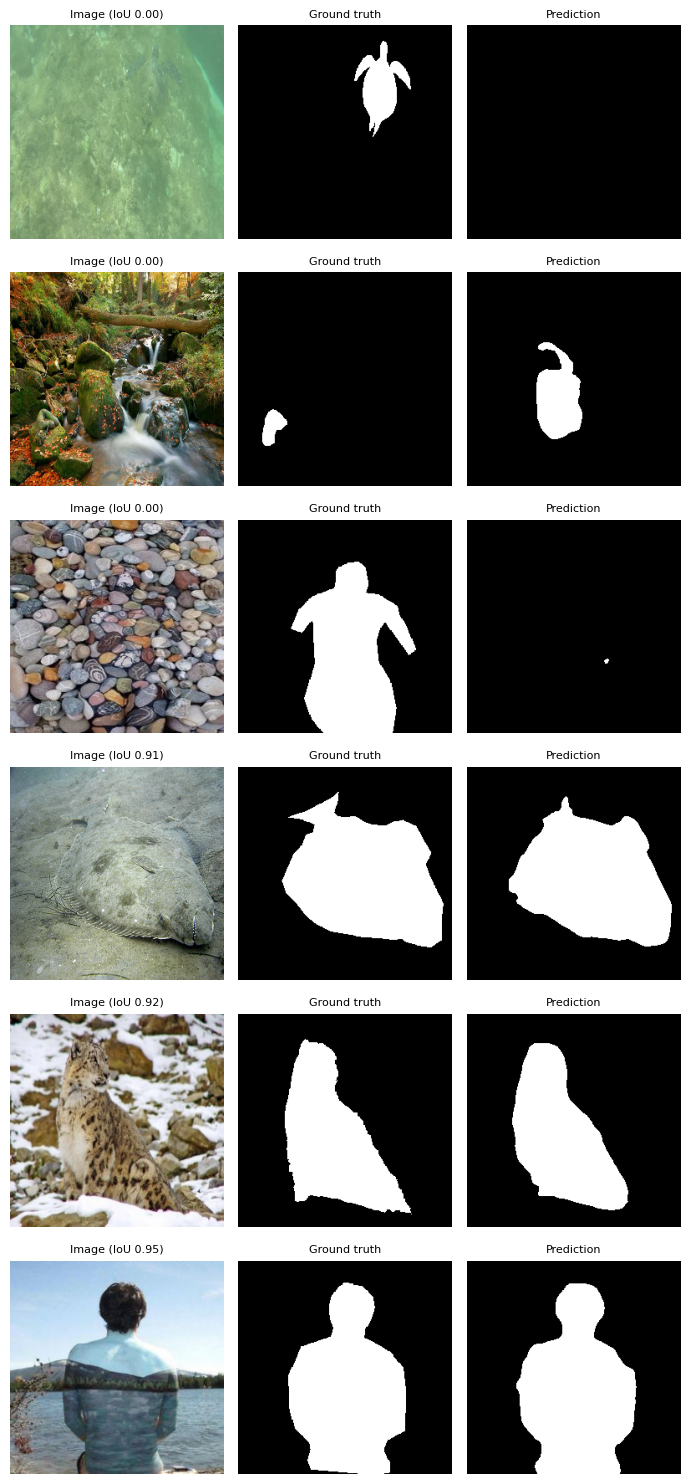

In [14]:
import matplotlib.pyplot as plt
d2 = df.sort_values("iou")
picks = list(d2.head(3).idx) + list(d2.tail(3).idx)
fig, ax = plt.subplots(6, 3, figsize=(7, 15))
for r, i in enumerate(picks):
    ip, mp = sp["test"][i]
    img = load_img(ip, False)
    gt = cv2.resize(cv2.imread(mp, 0), (SIZE, SIZE), interpolation=cv2.INTER_NEAREST) > 127
    x = torch.from_numpy(((img.astype(np.float32)/255.0 - MEAN)/STD).transpose(2, 0, 1))[None].to(device)
    with torch.no_grad():
        pr = torch.sigmoid(model(x))[0, 0].cpu().numpy() > BEST_THR
    iou = d2[d2.idx == i].iou.values[0]
    for c, (im, t) in enumerate([(img, f"Image (IoU {iou:.2f})"), (gt, "Ground truth"), (pr, "Prediction")]):
        ax[r, c].imshow(im, cmap=None if c == 0 else "gray"); ax[r, c].set_title(t, fontsize=8); ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(f"{D}/test_examples.png", dpi=150); plt.show()